# Homework 6: PyTorch On-Ramp
## Name: Jon Knapp
### Date: November 18, 2026
### Class: EE 513 Intro to Image Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Checking my work and my logic
* Checking and assistance with reflections

I used Claude (Anthropic) to write the PyTorch code and to draft the written answers, which I then reviewed and edited. Every PyTorch result is checked against something independent: the derivative against my own analytic expression (item 4), the gradient-descent fit against `np.linalg.lstsq` (item 5), the divergence threshold against the largest eigenvalue of the loss's Hessian (item 7), the convolution against `scipy.ndimage.correlate` with the border separated from the interior (items 8 and 9), and the parameter count against hand arithmetic (item 10). The answers to items 7, 9 and 13 that quote numbers are generated from the notebook's own variables, so they always match the printed output; the "Beyond the assignment" discussion and the reflections quote the outputs above them.

**Before running.** From the EE513 folder: re-download `pyproject.toml` and `uv.lock`, then `uv sync --group learning`. A bare `uv sync` removes torch again.

**Project 2.** The tensor conversions (`to_tensor`, `to_numpy`), `psnr`, and the small residual network here are the starting point for Part B. The convolution check in items 8 and 9 is the same check I'll use on the denoiser's ONNX export in Part C: compare against an independent implementation and separate the border from the interior.

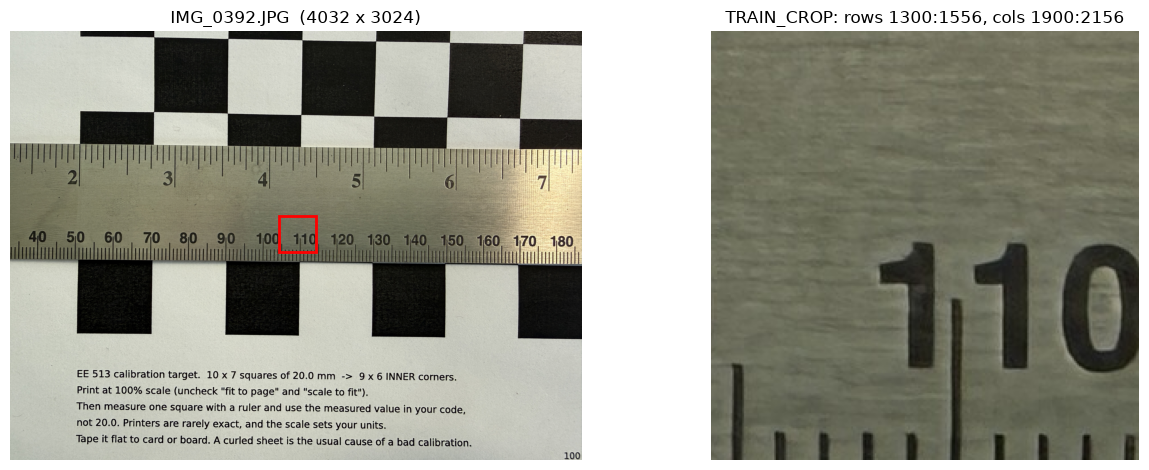

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Rectangle
from scipy.ndimage import correlate

EE513 = Path.cwd().resolve().parent
IMAGE_PATH = EE513 / "Project 1" / "Homework 1 Image Captures" / "IMG_0392.JPG"   # checkerboard + steel ruler
TRAIN_CROP = (slice(1300, 1556), slice(1900, 2156))      # 256 x 256 region with ruler digits and ticks (item 11)
SEED = 513
assert IMAGE_PATH.exists(), IMAGE_PATH

# The full image with the training crop outlined, and the crop at full resolution
preview = cv2.cvtColor(cv2.imread(str(IMAGE_PATH), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
rows, cols = TRAIN_CROP
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [4, 3]})
ax0.imshow(preview)
ax0.add_patch(Rectangle((cols.start, rows.start), cols.stop - cols.start, rows.stop - rows.start,
                        fill=False, edgecolor="red", linewidth=2))
ax0.set_title(f"{IMAGE_PATH.name}  ({preview.shape[1]} x {preview.shape[0]})")
ax1.imshow(preview[TRAIN_CROP])
ax1.set_title(f"TRAIN_CROP: rows {rows.start}:{rows.stop}, cols {cols.start}:{cols.stop}")
for ax in (ax0, ax1):
    ax.axis("off")
fig.tight_layout(); plt.show()

## Part 1: Tensors and layout

### Problem 1: Import torch and print its version, then report which device you'll be computing on. Check for CUDA and for Apple's MPS backend, and fall back to CPU.
_Deliverable: The printed version and device._

In [2]:
import platform
import torch
import torch.nn as nn

if torch.cuda.is_available():
    device = torch.device("cuda")
    name = torch.cuda.get_device_name(0)
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")            # no float64 on MPS: keep every tensor float32
    name = "Apple MPS"
else:
    device = torch.device("cpu")
    name = platform.processor() or platform.machine()

print(f"torch {torch.__version__}  (CUDA build: {torch.version.cuda}, ROCm build: {getattr(torch.version, 'hip', None)})")
print(f"device: {device}  ({name}); {torch.get_num_threads()} CPU threads; Python {platform.python_version()}")
_ = torch.manual_seed(SEED)

torch 2.14.0+cpu  (CUDA build: None, ROCm build: None)
device: cpu  (AMD64 Family 25 Model 33 Stepping 0, AuthenticAMD); 8 CPU threads; Python 3.12.15


### Problem 2: Load an image you already have, as a NumPy array in the usual height by width by channel layout, and convert it to a float32 tensor in PyTorch's batch, channel, height, width layout. Print the shape at each step.
_Deliverable: The two shapes, printed._

In [3]:
bgr = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_COLOR)              # OpenCV reads B, G, R
img = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0


def to_tensor(x_hwc, device=device):
    """H x W x C NumPy array -> 1 x C x H x W float32 tensor."""
    return torch.from_numpy(np.ascontiguousarray(x_hwc.transpose(2, 0, 1)))[None].to(device=device, dtype=torch.float32)


def to_numpy(t):
    """1 x C x H x W tensor -> H x W x C NumPy array (float32)."""
    return t.detach().to("cpu")[0].permute(1, 2, 0).numpy()


x = to_tensor(img)
print(f"NumPy  (H, W, C):    {img.shape}, {img.dtype}, range {img.min():.3f} to {img.max():.3f}")
print(f"tensor (N, C, H, W): {tuple(x.shape)}, {x.dtype}, on {x.device}")

NumPy  (H, W, C):    (3024, 4032, 3), float32, range 0.000 to 1.000
tensor (N, C, H, W): (1, 3, 3024, 4032), torch.float32, on cpu


### Problem 3: Convert the tensor back to a NumPy array in the original layout and assert that it equals what you started with.
_Deliverable: The assertion, passing._

In [4]:
back = to_numpy(x)
assert back.shape == img.shape and back.dtype == img.dtype
assert np.array_equal(back, img), "round trip changed the values"
# The check that would catch the classic bug: a plain reshape gives the right shape and wrong pixels.
wrong = x.detach().cpu()[0].reshape(img.shape).numpy()
print(f"Round trip passed: {back.shape}, bit for bit. "
      f"(A reshape instead of a permute also gives {wrong.shape}, but differs in "
      f"{(wrong != img).mean():.1%} of the values.)")

Round trip passed: (3024, 4032, 3), bit for bit. (A reshape instead of a permute also gives (3024, 4032, 3), but differs in 98.9% of the values.)


## Part 2: Autograd and a training loop

### Problem 4: Pick a scalar function of one variable whose derivative you can work out on paper. Evaluate the derivative at a point with autograd, and evaluate your own expression at the same point.
_Deliverable: Both values and the difference between them._

In [5]:
# f(x) = x^2 sin(x) + exp(-x/2)      =>      f'(x) = 2x sin(x) + x^2 cos(x) - exp(-x/2) / 2
x0 = 1.3
xt = torch.tensor(x0, dtype=torch.float64, requires_grad=True)
f = xt ** 2 * torch.sin(xt) + torch.exp(-xt / 2)
f.backward()
auto = xt.grad.item()
by_hand = 2 * x0 * np.sin(x0) + x0 ** 2 * np.cos(x0) - np.exp(-x0 / 2) / 2
print(f"f'({x0}) autograd: {auto:.17g}")
print(f"f'({x0}) by hand:  {by_hand:.17g}")
print(f"difference: {auto - by_hand:.3e}   (float64 epsilon {np.finfo(np.float64).eps:.2e})")

f'(1.3) autograd: 2.6963014140797466
f'(1.3) by hand:  2.6963014140797466
difference: 0.000e+00   (float64 epsilon 2.22e-16)


### Problem 5: Generate twenty noisy points on a straight line, then fit the slope and intercept by gradient descent, writing the loop yourself with an optimizer and a loss. Fit the same data with np.linalg.lstsq.
_Deliverable: Both pairs of coefficients, and how far apart they are._

In [6]:
rng = np.random.default_rng(SEED)
TRUE_SLOPE, TRUE_INTERCEPT = 2.5, -0.7
xs = np.linspace(-1, 1, 20)
ys = TRUE_SLOPE * xs + TRUE_INTERCEPT + rng.normal(0, 0.3, xs.size)

# Least squares, the reference answer
(ls_slope, ls_intercept), *_ = np.linalg.lstsq(np.c_[xs, np.ones_like(xs)], ys, rcond=None)


def fit_gd(lr, steps=1000):
    """Slope and intercept by plain gradient descent on the mean squared error. float64 so the
    comparison with lstsq is limited by convergence, not by float32 rounding."""
    X = torch.tensor(xs, dtype=torch.float64)
    Y = torch.tensor(ys, dtype=torch.float64)
    w = torch.zeros(2, dtype=torch.float64, requires_grad=True)       # slope, intercept
    opt = torch.optim.SGD([w], lr=lr)
    loss_fn = nn.MSELoss()
    losses = []
    for _ in range(steps):
        opt.zero_grad()
        loss = loss_fn(w[0] * X + w[1], Y)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return w.detach().numpy(), np.array(losses)


LR = 0.1
(gd_slope, gd_intercept), gd_losses = fit_gd(LR)
coef = pd.DataFrame({"slope": [gd_slope, ls_slope, TRUE_SLOPE], "intercept": [gd_intercept, ls_intercept, TRUE_INTERCEPT]},
                    index=[f"gradient descent (SGD, lr {LR}, 1000 steps)", "np.linalg.lstsq", "true line (before noise)"])
display(coef.style.format("{:.12f}"))
gap = max(abs(gd_slope - ls_slope), abs(gd_intercept - ls_intercept))
print(f"Largest difference between the two fits: {gap:.2e}")

,slope,intercept
"gradient descent (SGD, lr 0.1, 1000 steps)",2.388715440542,-0.721984873125
np.linalg.lstsq,2.388715440542,-0.721984873125
true line (before noise),2.500000000000,-0.700000000000


Largest difference between the two fits: 2.66e-15


### Problem 6: Plot the loss against iteration for that fit.
_Deliverable: One figure._

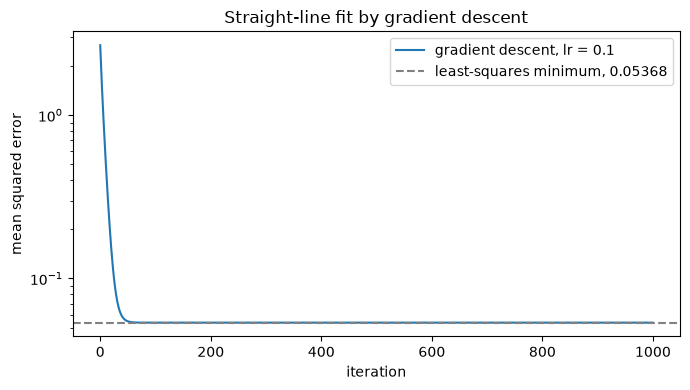

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(gd_losses, lw=1.5, label=f"gradient descent, lr = {LR}")
ls_loss = np.mean((ls_slope * xs + ls_intercept - ys) ** 2)
ax.axhline(ls_loss, ls="--", color="gray", label=f"least-squares minimum, {ls_loss:.5f}")
ax.set_xlabel("iteration"); ax.set_ylabel("mean squared error")
ax.set_title("Straight-line fit by gradient descent")
ax.legend()
fig.tight_layout(); fig.savefig("hw6_item6_loss.png", dpi=150); plt.show()

### Problem 7: Raise the learning rate until the fit stops converging, and say what the loss curve does when it fails.
_Deliverable: The learning rate where it broke, and one sentence._

Largest Hessian eigenvalue 2.0000 -> predicted limit lr < 1.0000


lr,final loss,converged
0.100000,0.05368,True
0.500000,0.05368,True
0.900000,0.05368,True
0.980000,0.05368,True
1.000000,0.5749,False
1.020000,3.136e+06,False
1.100000,1.703e+31,False
1.500000,3.365e+119,False


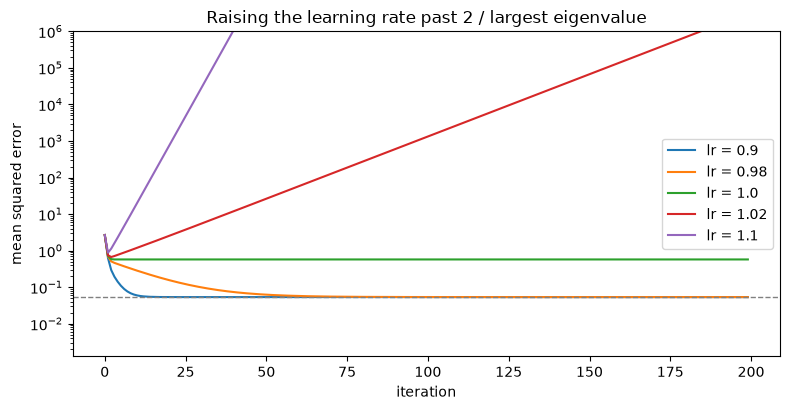

In [8]:
# Prediction: for a quadratic loss, gradient descent is stable only if lr < 2 / (largest eigenvalue
# of the Hessian). Here the Hessian of the MSE is (2/N) X^T X with X = [x, 1].
Xd = np.c_[xs, np.ones_like(xs)]
lam_max = np.linalg.eigvalsh(2 / xs.size * Xd.T @ Xd).max()
print(f"Largest Hessian eigenvalue {lam_max:.4f} -> predicted limit lr < {2 / lam_max:.4f}")

rates = [0.1, 0.5, 0.9, 0.98, 1.0, 1.02, 1.1, 1.5]
rows, curves = [], {}
for lr in rates:
    (s, b), L = fit_gd(lr, steps=200)
    curves[lr] = L
    rows.append({"lr": lr, "final loss": L[-1], "converged": bool(np.isfinite(L[-1]) and L[-1] < 2 * ls_loss)})
lr_table = pd.DataFrame(rows)
display(lr_table.style.format({"final loss": "{:.4g}"}).hide(axis="index"))
LR_BREAK = lr_table.loc[~lr_table.converged, "lr"].min()

fig, ax = plt.subplots(figsize=(8, 4.2))
for lr in (0.9, 0.98, 1.0, 1.02, 1.1):
    ax.semilogy(curves[lr], label=f"lr = {lr}")
ax.axhline(ls_loss, ls="--", color="gray", lw=1)
ax.set_xlabel("iteration"); ax.set_ylabel("mean squared error"); ax.set_ylim(top=1e6)
ax.set_title("Raising the learning rate past 2 / largest eigenvalue")
ax.legend(); fig.tight_layout(); fig.savefig("hw6_item7_lr.png", dpi=150); plt.show()

In [9]:
L_at = lr_table.set_index("lr")["final loss"]
display(Markdown(
    f"The fit stopped converging at **lr = {LR_BREAK:g}**; the prediction from the Hessian is 2/λ_max = {2 / lam_max:.3f}. "
    f"The steepest direction here is the intercept (for x centered on zero the Hessian is diagonal, with eigenvalues "
    f"2·mean(x²) and 2). At exactly the limit the intercept's error flips sign every step without shrinking, so the loss "
    f"stalls at {L_at[1.0]:.3g} instead of the minimum {ls_loss:.3g}. Above it the error grows each step, and the loss "
    f"climbs exponentially, a straight line upward on the log plot ({L_at[1.1]:.1e} after 200 steps at lr = 1.1) "
    f"rather than leveling off."))

The fit stopped converging at **lr = 1**; the prediction from the Hessian is 2/λ_max = 1.000. The steepest direction here is the intercept (for x centered on zero the Hessian is diagonal, with eigenvalues 2·mean(x²) and 2). At exactly the limit the intercept's error flips sign every step without shrinking, so the loss stalls at 0.575 instead of the minimum 0.0537. Above it the error grows each step, and the loss climbs exponentially, a straight line upward on the log plot (1.7e+31 after 200 steps at lr = 1.1) rather than leveling off.

## Part 3: Layers on an image

### Problem 8: Build a nn.Conv2d whose weights you set by hand to a 5 by 5 Gaussian kernel, with no bias, and apply it to your image from item 2. Apply the same kernel with scipy.ndimage.correlate or cv2.filter2D. Match the padding and the border handling between the two.
_Deliverable: The largest absolute difference between the two results, and the value of np.finfo(np.float32).eps to compare it against._

In [10]:
SIGMA = 1.0
g1 = np.exp(-0.5 * (np.arange(-2, 3) / SIGMA) ** 2)
kernel = np.outer(g1, g1).astype(np.float32)
kernel /= kernel.sum()

conv = nn.Conv2d(3, 3, kernel_size=5, padding=2, padding_mode="zeros", groups=3, bias=False).to(device)
with torch.no_grad():
    conv.weight.copy_(torch.from_numpy(kernel).expand(3, 1, 5, 5))     # one 5x5 kernel per channel
    torch_out = to_numpy(conv(x))

# scipy with the same convention: zero padding ("constant", cval 0), channel by channel
scipy_out = np.dstack([correlate(img[..., c], kernel, mode="constant", cval=0.0) for c in range(3)])

EPS32 = np.finfo(np.float32).eps
d8 = np.abs(torch_out - scipy_out)
print(f"Largest |torch - scipy|, both zero padded: {d8.max():.3e}   "
      f"(np.finfo(np.float32).eps = {EPS32:.3e}, so {d8.max() / EPS32:.1f} eps)")

Largest |torch - scipy|, both zero padded: 2.980e-07   (np.finfo(np.float32).eps = 1.192e-07, so 2.5 eps)


### Problem 9: If that difference is larger than floating point rounding, find out why before you go on. Separate the border from the interior before you conclude anything.
_Deliverable: One sentence on what caused it, or a statement that there was no disagreement._

In [11]:
def border_interior(d, b=2):
    inner = d[b:-b, b:-b]
    edge = d.copy(); edge[b:-b, b:-b] = 0
    return edge.max(), inner.max()


# What the same comparison looks like with the border conventions NOT matched (scipy's default).
scipy_reflect = np.dstack([correlate(img[..., c], kernel) for c in range(3)])     # mode="reflect"
rows = []
for label, ref_ in (("scipy zero padding (matched)", scipy_out), ("scipy default 'reflect' (not matched)", scipy_reflect)):
    edge, inner = border_interior(np.abs(torch_out - ref_))
    rows.append({"comparison": label, "border, outer 2 px": edge, "interior": inner,
                 "interior / float32 eps": inner / EPS32})
display(pd.DataFrame(rows).style.format("{:.3e}", subset=["border, outer 2 px", "interior"])
        .format("{:.1f}", subset=["interior / float32 eps"]).hide(axis="index"))

comparison,"border, outer 2 px",interior,interior / float32 eps
scipy zero padding (matched),2.384e-07,2.980e-07,2.5
scipy default 'reflect' (not matched),4.103e-01,2.980e-07,2.5


In [12]:
e_m, i_m = border_interior(d8)
display(Markdown(
    f"There was no disagreement beyond float32 rounding once the padding was matched: the largest difference is "
    f"{d8.max():.1e} ({d8.max() / EPS32:.1f} float32 eps), the same size at the border ({e_m:.1e}) and in the interior "
    f"({i_m:.1e}), which is what summing 25 float32 products in a different order produces. With scipy's default "
    f"`reflect` border against PyTorch's zero padding, the interior still agrees but the outer two pixels differ by up "
    f"to {rows[1]['border, outer 2 px']:.2f}, which is the mistake this item is built to catch."))

There was no disagreement beyond float32 rounding once the padding was matched: the largest difference is 3.0e-07 (2.5 float32 eps), the same size at the border (2.4e-07) and in the interior (3.0e-07), which is what summing 25 float32 products in a different order produces. With scipy's default `reflect` border against PyTorch's zero padding, the interior still agrees but the outer two pixels differ by up to 0.41, which is the mistake this item is built to catch.

### Problem 10: Define a small convolutional network as an nn.Module, three or four layers, and print its total number of parameters. Then work out by hand how many parameters one of those layers has, and check that your arithmetic agrees with what PyTorch reports for that layer.
_Deliverable: The total, and your arithmetic for one layer._

In [13]:
class SmallDenoiser(nn.Module):
    """Four 3x3 convolutions, 32 channels, ReLU between. It predicts the noise, so the output is
    the input minus what the network produced (residual learning, as in DnCNN)."""

    def __init__(self, channels=3, width=32, depth=4):
        super().__init__()
        layers = [nn.Conv2d(channels, width, 3, padding=1), nn.ReLU()]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(width, width, 3, padding=1), nn.ReLU()]
        layers += [nn.Conv2d(width, channels, 3, padding=1)]
        self.body = nn.Sequential(*layers)

    def forward(self, noisy):
        return noisy - self.body(noisy)


def count_params(m):
    return sum(p.numel() for p in m.parameters())


net = SmallDenoiser().to(device)
print(net)
print(f"\nTotal parameters: {count_params(net):,}")
per_layer = [(n, m) for n, m in net.named_modules() if isinstance(m, nn.Conv2d)]
for n, m in per_layer:
    print(f"  {n:8s} {tuple(m.weight.shape)}  {count_params(m):,}")

# By hand, the second convolution (32 -> 32, 3 x 3): one 3x3 kernel per (input, output) channel pair, plus one bias per output
by_hand = 32 * 32 * 3 * 3 + 32
reported = count_params(per_layer[1][1])
print(f"\nLayer {per_layer[1][0]}: 32 x 32 x 3 x 3 + 32 = {by_hand:,}; PyTorch reports {reported:,}")
assert by_hand == reported

SmallDenoiser(
  (body): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(32, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)

Total parameters: 20,259
  body.0   (32, 3, 3, 3)  896
  body.2   (32, 32, 3, 3)  9,248
  body.4   (32, 32, 3, 3)  9,248
  body.6   (3, 32, 3, 3)  867

Layer body.2: 32 x 32 x 3 x 3 + 32 = 9,248; PyTorch reports 9,248


### Problem 11: Add Gaussian noise to your image, then train your network to predict the clean image from the noisy one. One image is enough and it will overfit, which is fine here. Plot the loss.
_Deliverable: One loss curve._

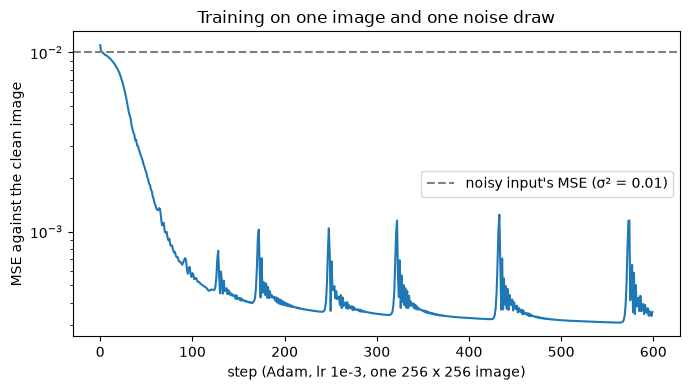

In [14]:
NOISE_SD = 0.10            # on the [0, 1] scale of the 8-bit image
STEPS = 600

clean_np = img[TRAIN_CROP]
clean = to_tensor(clean_np)
g = torch.Generator(device="cpu").manual_seed(SEED)
noisy = (clean.cpu() + NOISE_SD * torch.randn(clean.shape, generator=g)).to(device)

torch.manual_seed(SEED)
net = SmallDenoiser().to(device)
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
train_loss = []
for step in range(STEPS):
    opt.zero_grad()
    loss = loss_fn(net(noisy), clean)
    loss.backward()
    opt.step()
    train_loss.append(loss.item())

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(train_loss)
ax.axhline(NOISE_SD ** 2, ls="--", color="gray", label=f"noisy input's MSE (σ² = {NOISE_SD ** 2:g})")
ax.set_xlabel("step (Adam, lr 1e-3, one 256 x 256 image)"); ax.set_ylabel("MSE against the clean image")
ax.set_title("Training on one image and one noise draw")
ax.legend(); fig.tight_layout(); fig.savefig("hw6_item11_train_loss.png", dpi=150); plt.show()

**Note.** The spikes are Adam overshooting. PSNR (item 12) is computed from the weights at the final step, where the loss sits slightly above the curve's floor.

### Problem 12: Report PSNR of the noisy image and of your network's output, both against the clean original, and state the peak value you used.
_Deliverable: Two PSNR values._

Peak = 1.0 (white of the 8-bit image scaled to [0, 1]); no clipping
PSNR noisy input:    20.02 dB
PSNR network output: 34.77 dB  (+14.75 dB)


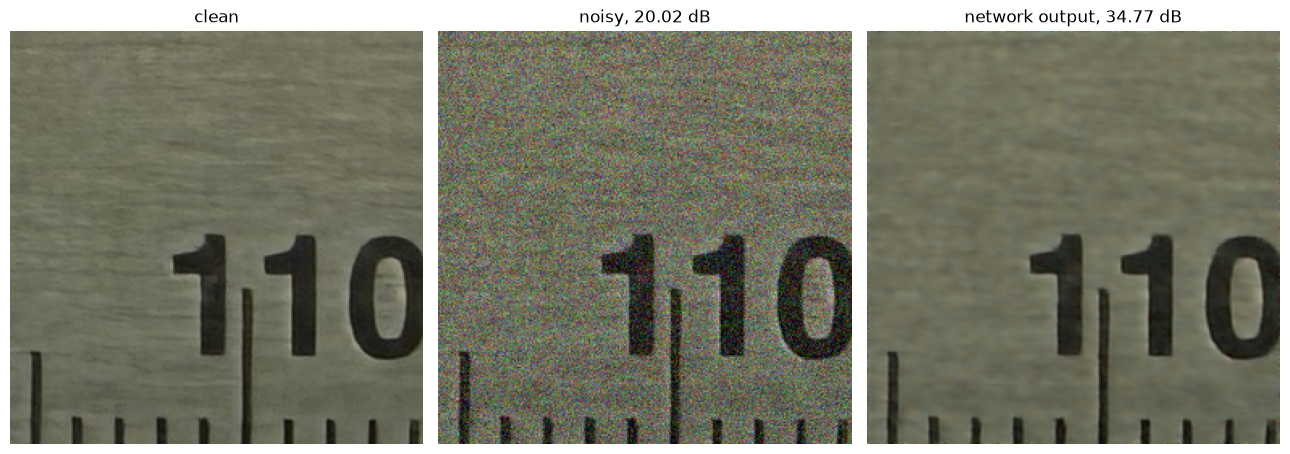

In [15]:
def psnr(est, ref, peak=1.0):
    mse = float(np.mean((np.asarray(est, np.float64) - np.asarray(ref, np.float64)) ** 2))
    return 10 * np.log10(peak ** 2 / mse)


PEAK = 1.0
with torch.no_grad():
    den = to_numpy(net(noisy))
noisy_np = to_numpy(noisy)
psnr_noisy, psnr_out = psnr(noisy_np, clean_np, PEAK), psnr(den, clean_np, PEAK)
print(f"Peak = {PEAK} (white of the 8-bit image scaled to [0, 1]); no clipping")
print(f"PSNR noisy input:    {psnr_noisy:.2f} dB")
print(f"PSNR network output: {psnr_out:.2f} dB  ({psnr_out - psnr_noisy:+.2f} dB)")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, im_, t in zip(axes, (clean_np, noisy_np, den),
                      ("clean", f"noisy, {psnr_noisy:.2f} dB", f"network output, {psnr_out:.2f} dB")):
    ax.imshow(np.clip(im_, 0, 1)); ax.set_title(t); ax.axis("off")
fig.tight_layout(); fig.savefig("hw6_item12_denoised.png", dpi=150); plt.show()

### Problem 13: Your network saw one image and one noise draw, several hundred times. Say what that means for the number you just reported, and what you'd expect on a fresh noise draw of the same image.
_Deliverable: Two or three sentences._

In [16]:
# Testing the expectation instead of only stating it: five fresh noise draws of the same image.
fresh = []
with torch.no_grad():
    for k in range(5):
        gk = torch.Generator(device="cpu").manual_seed(1000 + k)
        nk = (clean.cpu() + NOISE_SD * torch.randn(clean.shape, generator=gk)).to(device)
        fresh.append((psnr(to_numpy(nk), clean_np), psnr(to_numpy(net(nk)), clean_np)))
fresh = np.array(fresh)
print(f"Fresh noise draws (n = 5): input {fresh[:, 0].mean():.2f} ± {fresh[:, 0].std(ddof=1):.2f} dB, "
      f"output {fresh[:, 1].mean():.2f} ± {fresh[:, 1].std(ddof=1):.2f} dB")
display(Markdown(
    f"The {psnr_out:.2f} dB is a training score, not a test score: the network was graded on the exact image and noise "
    f"draw it was fitted to, {STEPS} times, so part of the gain can be memorizing that particular noise pattern rather "
    f"than learning to remove noise. On a fresh noise draw of the same image I'd expect a lower number, and five fresh "
    f"draws give {fresh[:, 1].mean():.2f} ± {fresh[:, 1].std(ddof=1):.2f} dB, "
    f"{psnr_out - fresh[:, 1].mean():.2f} dB below the training draw. It still beats the noisy input "
    f"({fresh[:, 0].mean():.2f} dB) by a wide margin, so most of the gain is real noise removal; but the network "
    f"has also fitted this image's content, which makes even the fresh-draw number optimistic for any other image."))

Fresh noise draws (n = 5): input 19.99 ± 0.01 dB, output 34.53 ± 0.05 dB


The 34.77 dB is a training score, not a test score: the network was graded on the exact image and noise draw it was fitted to, 600 times, so part of the gain can be memorizing that particular noise pattern rather than learning to remove noise. On a fresh noise draw of the same image I'd expect a lower number, and five fresh draws give 34.53 ± 0.05 dB, 0.24 dB below the training draw. It still beats the noisy input (19.99 dB) by a wide margin, so most of the gain is real noise removal; but the network has also fitted this image's content, which makes even the fresh-draw number optimistic for any other image.

## Beyond the assignment: what 34.5 dB means
How does the network compare with the Gaussian filter from item 8 and with BM3D, and does it carry over to parts of the photo it never saw?

,"training crop, fresh noise",unseen: ruler digits,unseen: checkerboard corner
noisy input,19.98 dB,19.99 dB,19.98 dB
5x5 Gaussian (item 8),29.77 dB,29.92 dB,29.74 dB
BM3D (σ given),35.87 dB,36.29 dB,35.52 dB
this network,34.57 dB,34.68 dB,28.44 dB


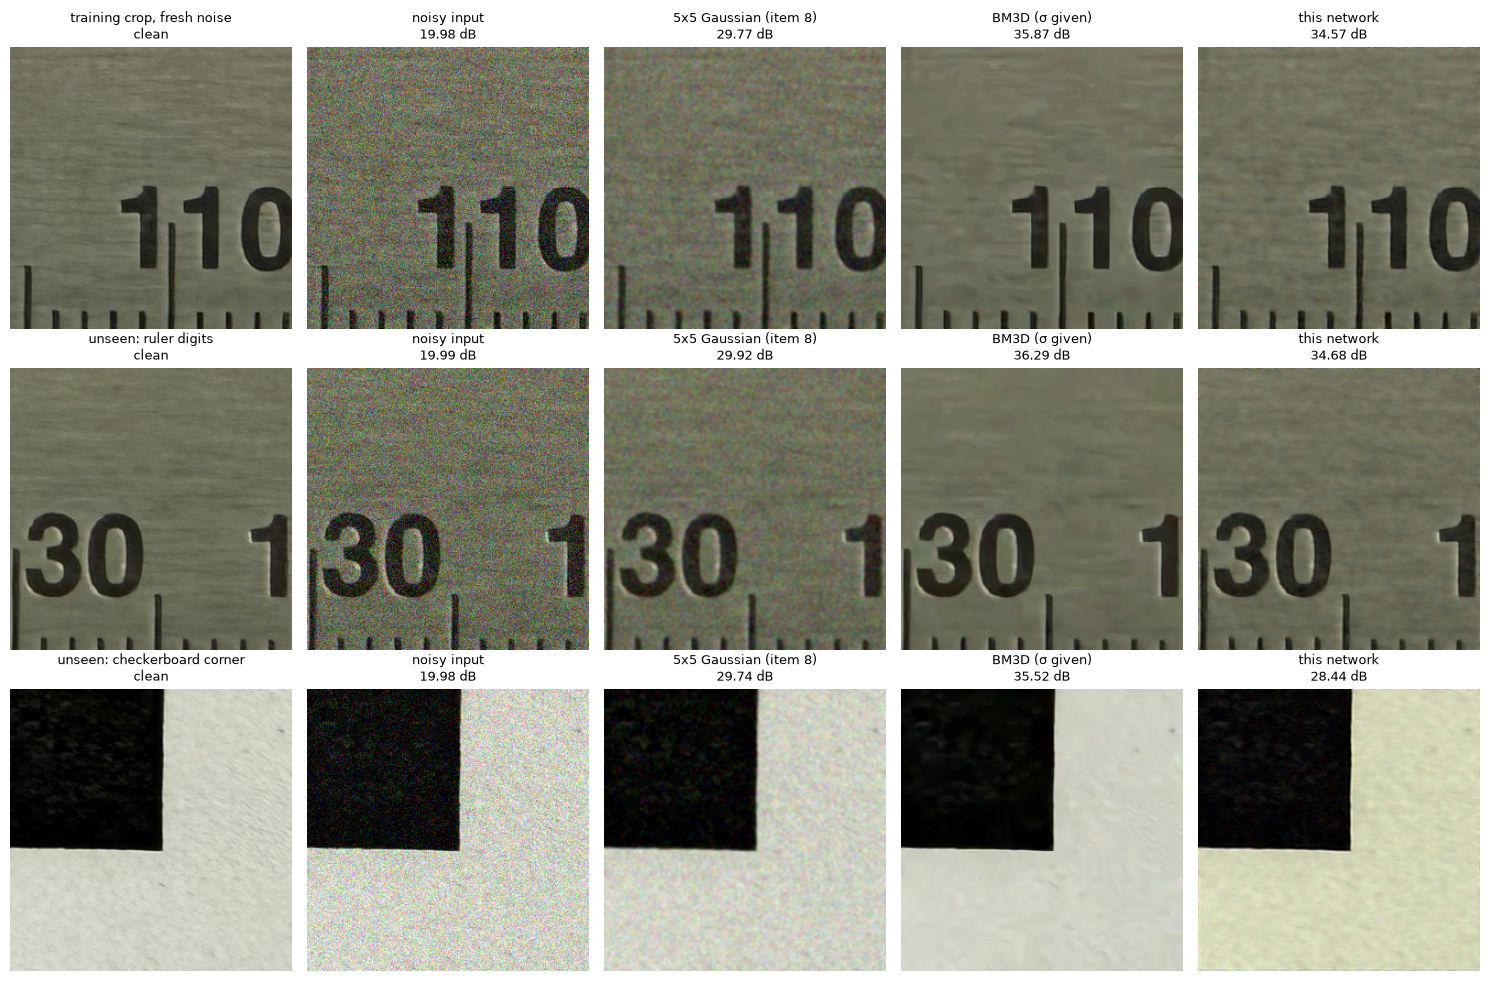

mean error per channel (R, G, B): [ 0.016  0.016 -0.031]


In [17]:
import bm3d

CROPS = {
    "training crop, fresh noise": TRAIN_CROP,
    "unseen: ruler digits": (slice(1300, 1556), slice(2560, 2816)),
    "unseen: checkerboard corner": (slice(2000, 2256), slice(1900, 2156)),
}


def gaussian5(z):
    """The 5 x 5 Gaussian from item 8, reflect border, channel by channel."""
    return np.dstack([correlate(z[..., c], kernel) for c in range(3)])


rng_eval = np.random.default_rng(2000)              # a noise draw the network never trained on
results, panels = {}, {}
for name, crop in CROPS.items():
    c_np = img[crop]
    n_np = c_np + NOISE_SD * rng_eval.standard_normal(c_np.shape).astype(np.float32)
    with torch.no_grad():
        net_np = to_numpy(net(to_tensor(n_np)))
    outs = {"noisy input": n_np,
            "5x5 Gaussian (item 8)": gaussian5(n_np),
            "BM3D (σ given)": bm3d.bm3d_rgb(n_np, NOISE_SD),
            "this network": net_np}
    results[name] = {k: psnr(v, c_np) for k, v in outs.items()}
    panels[name] = (c_np, outs)

display(pd.DataFrame(results).style.format("{:.2f} dB"))

fig, axes = plt.subplots(len(panels), 5, figsize=(15, 3.3 * len(panels)))
for r, (name, (c_np, outs)) in enumerate(panels.items()):
    for ax, (title, im_) in zip(axes[r], [(f"{name}\nclean", c_np), *outs.items()]):
        ax.imshow(np.clip(im_, 0, 1)); ax.axis("off")
        ax.set_title(title if "clean" in title else f"{title}\n{psnr(im_, c_np):.2f} dB", fontsize=9)
fig.tight_layout(); fig.savefig("hw6_extra_baselines.png", dpi=150); plt.show()

# The network's color bias on the white paper (third bullet below)
c_np, outs = panels["unseen: checkerboard corner"]
print("mean error per channel (R, G, B):", (outs["this network"] - c_np).mean(axis=(0, 1)).round(3))

### What the baselines show

- **BM3D wins on every crop.** It needs no training and still beats the network by 1.3 dB on the training crop (35.87 vs. 34.57 dB) and by 1.6 dB on the unseen ruler digits. It has one advantage: it was given the true σ = 0.1, and white Gaussian noise of known σ is the case BM3D was designed for. Real camera noise depends on the signal and its σ isn't known, so this setting flatters BM3D and won't carry over to Project 2.
- **The network carries over to similar content.** On ruler digits it never saw, it scores 34.68 dB, the same as on its own crop with fresh noise (34.57 dB). So it learned to denoise brushed steel with dark digits, not just the one patch it trained on.
- **It fails on content unlike its training crop.** On the checkerboard corner it drops to 28.44 dB, below even the 5×5 Gaussian (29.74 dB). The output is smooth, but the white paper comes out yellow: the mean error per channel is +0.016 (R), +0.016 (G) and −0.031 (B). That bias accounts for about a third of the squared error. Removing it would raise the network to about 30.3 dB, enough to beat the Gaussian but still 5 dB short of BM3D. The training crop held only mid-gray steel and dark digits, so the network never saw near-white pixels and never learned to keep them neutral.
- **The fixed Gaussian filter doesn't depend on content.** It scores about 29.8 dB on all three crops because it does the same thing everywhere: it removes some noise and blurs edges equally.

This bears out item 13 with one qualification. The training-crop score is optimistic for content the network hasn't seen, but not for more of the same kind of content. A 20,000-parameter network trained on one 256 × 256 patch learns that patch's statistics, not a general denoiser. That's why a learned denoiser needs varied training data, and why a classical baseline is worth reporting next to it.

## Part 4: Reflections
### Problem 14: What did you learn from this assignment?
_Deliverable: A brief written response._

- **Layout bugs don't crash**

  An H × W × C array reshaped (instead of permuted) to C × H × W has the right shape and produces a picture, just a wrong one. A round trip with `np.array_equal` is the only check that catches it.

- **Autograd is checkable, and checking it is cheap**

  The autograd derivative matched my hand derivative exactly, to all 17 digits in float64, and the gradient-descent line fit matched `lstsq` once it had converged.

- **The learning-rate limit is predictable**

  For a quadratic loss, gradient descent diverges once the step exceeds 2 / (largest Hessian eigenvalue). The fit broke right at the predicted value, and the failure is exponential growth of the loss, not a plateau.

- **`nn.Conv2d` is cross-correlation with zero padding, and it mixes channels unless `groups` says otherwise**

  Matching scipy to float32 rounding took the same padding on both sides. With scipy's default `reflect`, the interior still agreed and only the border was off, which is why the border has to be checked separately.

- **A score on the training draw is not a denoising result**

  A fresh noise draw of the same crop cost only 0.24 dB, but a crop unlike the training one (the checkerboard) cost about 6 dB, and BM3D, with no training at all, beat the network on every crop. The 34.5 dB only meant something once it sat next to a classical baseline and an unseen crop. That is the trap Project 2 warns about with synthetic test data, and why Part B evaluates on real held-out burst pairs.

### Problem 15: What questions do you have for me?
_Deliverable: A brief written response._

I have no questions at this time.

### Problem 16: If you used AI tools, say what you used them for and how you verified the output.
_Deliverable: Two sentences, or a statement that you didn't use them._

I used Claude (Anthropic) to write the PyTorch code and to draft the written answers, which I reviewed and edited. I verified each result against an independent reference (my hand derivative, `np.linalg.lstsq`, the Hessian's eigenvalue limit, `scipy.ndimage.correlate` with the border separated from the interior, hand-counted parameters, and a layout round trip with `np.array_equal`), and the item answers that quote numbers are generated from the notebook's variables so they match the output.